<h1>Train — EfficientNet-B0</h1>

Trains and evaluates EfficientNet-B0 using the tuned hyperparameters from `ARCH_HYPERPARAMS["efficientnet_b0"]`, then saves its results and weights to disk for the results notebook.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): chronological
Train-time augmentation: on
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']
Train: 1348 | Val: 323 | Test: 856


## Build dataloaders + class weights for this architecture

In [2]:
cfg = ARCH_HYPERPARAMS["efficientnet_b0"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"EfficientNet-B0: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders — its own (capped) batch size, and
# (for InceptionNet v3) its own image size.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

EfficientNet-B0: micro batch = 16, accumulation steps = 6 (effective batch size ≈ 96, tuned value = 96)


## Define the model

In [3]:
# ---------------------------------------------------------
# Define the CNN (Transfer Learning with EfficientNet-B0)
# ---------------------------------------------------------
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)

# EfficientNet's classifier is nn.Sequential(Dropout, Linear) — swap out
# just the Linear layer for our (optionally deeper) classifier head, same
# as the fc/classifier swaps used for the other architectures.
in_f = model.classifier[1].in_features
model.classifier[1] = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[EfficientNet-B0] Using gradient accumulation: 6 micro-batches per optimizer step (effective batch size ≈ micro_batch x 6).


[EfficientNet-B0] Epoch   1/100 | LR: 8.76e-04 | train loss 0.8335 acc 0.596 | val loss 0.6385 acc 0.728 *


[EfficientNet-B0] Epoch   2/100 | LR: 8.76e-04 | train loss 0.6232 acc 0.726 | val loss 0.6285 acc 0.762 *


[EfficientNet-B0] Epoch   3/100 | LR: 8.76e-04 | train loss 0.4797 acc 0.792 | val loss 0.5359 acc 0.789 *


[EfficientNet-B0] Epoch   4/100 | LR: 8.76e-04 | train loss 0.4164 acc 0.812 | val loss 0.4507 acc 0.839 *


...

[EfficientNet-B0] Epoch  14/100 | LR: 8.76e-04 | train loss 0.1538 acc 0.931 | val loss 0.4566 acc 0.858


[EfficientNet-B0] Epoch  15/100 | LR: 8.76e-04 | train loss 0.2156 acc 0.898 | val loss 0.5698 acc 0.830


[EfficientNet-B0] Epoch  16/100 | LR: 8.76e-04 | train loss 0.1964 acc 0.915 | val loss 0.4777 acc 0.842


[EfficientNet-B0] Epoch  17/100 | LR: 8.76e-04 | train loss 0.1701 acc 0.925 | val loss 0.5796 acc 0.805


[EfficientNet-B0] Epoch  18/100 | LR: 8.76e-04 | train loss 0.1505 acc 0.940 | val loss 0.7363 acc 0.780

[EfficientNet-B0] No val loss improvement for 10 epochs — stopping early at epoch 18.

[EfficientNet-B0] Restored best checkpoint (val loss = 0.3964)


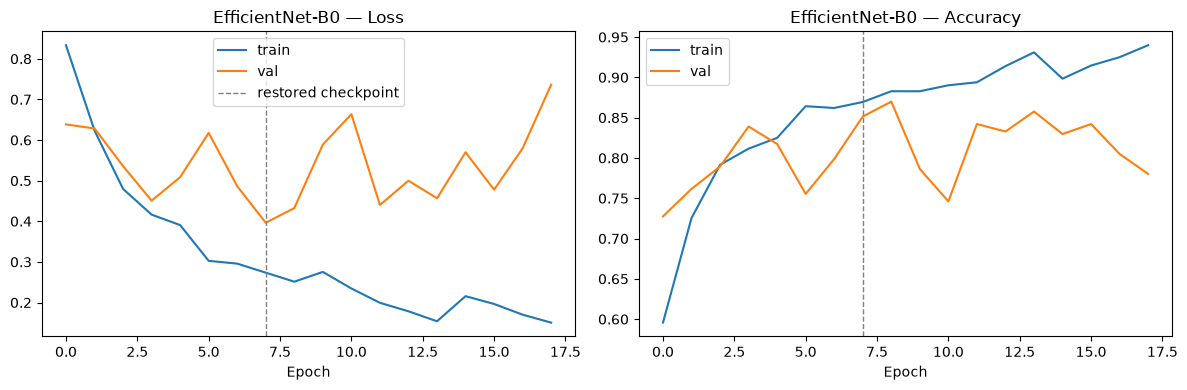

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "EfficientNet-B0", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "EfficientNet-B0")

## Evaluate on the test set

[EfficientNet-B0] Test accuracy: 0.780


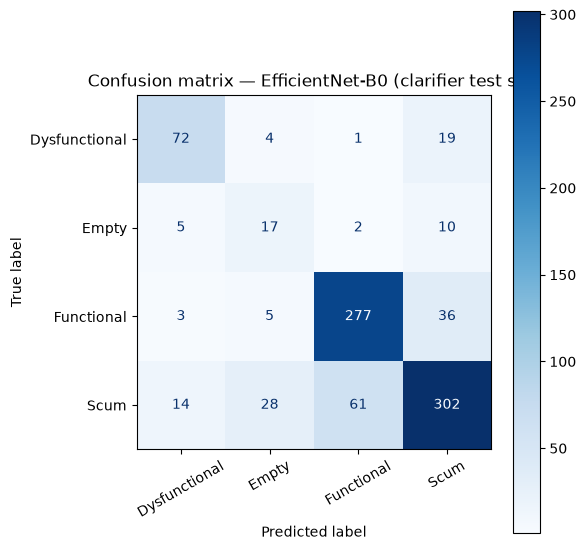

               precision    recall  f1-score   support

Dysfunctional      0.766     0.750     0.758        96
        Empty      0.315     0.500     0.386        34
   Functional      0.812     0.863     0.837       321
         Scum      0.823     0.746     0.782       405

     accuracy                          0.780       856
    macro avg      0.679     0.715     0.691       856
 weighted avg      0.792     0.780     0.784       856



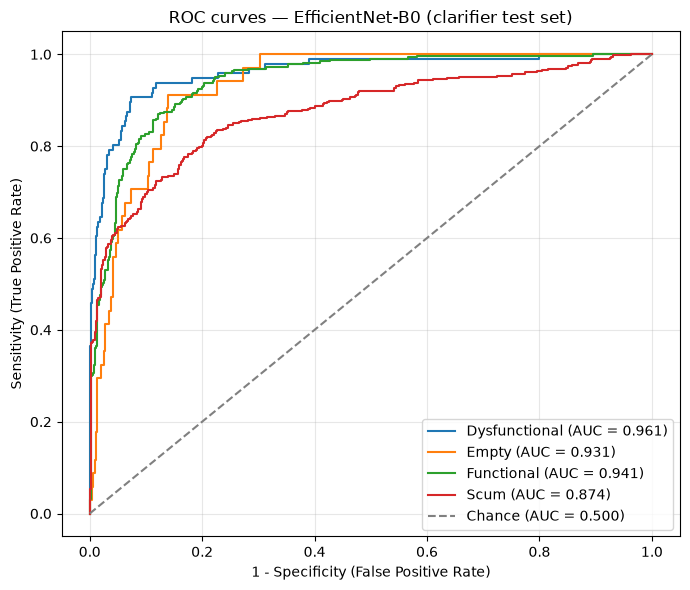

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.961
  Empty          : 0.931
  Functional     : 0.941
  Scum           : 0.874

Mean AUC (over 4/4 classes with test examples): 0.927


(np.float64(0.780373831775701),
 {'Dysfunctional': 0.9606633771929824,
  'Empty': 0.9311578646056963,
  'Functional': 0.9412699799109093,
  'Scum': 0.8743094905696532})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "EfficientNet-B0", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

In [6]:
save_result("EfficientNet-B0", "efficientnet_b0")

Saved results to ../results/clarifier_aug/results_clarifier_efficientnet_b0_chronological.pkl


Saved model weights to ../models/pad/clarifier_efficientnet_b0_cnn.pt
